# ДЗ 3. Фреймворк, критик и план

Агент из ДЗ 2, 42 вопроса. Один фреймворк — LangGraph.
Два паттерна — критик с источниками и план перед исполнением.

По умолчанию используются сохранённые ответы. Для нового платного прогона — `RUN_LIVE = True`.
Новый прогон сохраняется отдельно в `runs/`, старые результаты не меняются.

In [1]:
import os, re, json, time, hashlib, threading, contextlib, contextvars
from pathlib import Path
from dataclasses import dataclass, field
from datetime import datetime
from concurrent.futures import ThreadPoolExecutor
from typing import TypedDict

import httpx
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from pydantic import BaseModel, Field
from langgraph.graph import StateGraph, START, END
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'data/questions.jsonl').exists():
    raise RuntimeError('Откройте ноутбук из папки hw_3')

RUN_LIVE = False
WORKERS = 6
MAX_DOLLARS = 2.0
RESULTS_DIR = ROOT / ('runs/' + datetime.now().strftime('%Y%m%d_%H%M%S') if RUN_LIVE else 'results')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
load_dotenv(ROOT / '.env')
KEY = os.getenv('OPENROUTER_API_KEY') or os.getenv('OPEN_ROUTER_API_KEY')
if RUN_LIVE:
    assert KEY, 'Добавьте OPENROUTER_API_KEY в .env'

CHEAP = 'openai/gpt-4o-mini'
STRONG = 'anthropic/claude-sonnet-4.6'
EMBED = 'openai/text-embedding-3-small'
LIMIT_ANSWER = 'NOT_FOUND (достигнут лимит вызовов модели)'
CONFIGS = ['bare', 'langgraph', 'critic', 'plan', 'strong']
LABELS = {'bare': 'Голый цикл, mini', 'langgraph': 'LangGraph, mini',
          'critic': 'Критик с опорой, mini', 'plan': 'План + агент, mini',
          'strong': 'Sonnet без инструментов'}

In [2]:
def load_jsonl(path):
    return [json.loads(line) for line in Path(path).read_text().splitlines() if line.strip()]

def write_json(path, data):
    Path(path).write_text(json.dumps(data, ensure_ascii=False, indent=2), encoding='utf-8')

## 1. HTTP-счётчик

Один `httpx.Client` для всех исполнений и эмбеддингов.
Крючок на ответ сохраняет `usage`, токены, цену и метку конфигурации.
`ContextVar` разделяет параллельные вопросы. Лимит проверяется перед запросом.

In [3]:
@dataclass
class RunContext:
    config: str
    question_id: str
    max_calls: int = 24
    attempts: int = 0
    call_ids: list = field(default_factory=list)
    limited: bool = False

CURRENT = contextvars.ContextVar("run_context")

class CallLimit(RuntimeError):
    pass

@contextlib.contextmanager
def run_scope(config, question_id, max_calls=24):
    context = RunContext(config, question_id, max_calls)
    token = CURRENT.set(context)
    try:
        yield context
    finally:
        CURRENT.reset(token)

In [4]:
CALLS = load_jsonl(RESULTS_DIR / 'calls.jsonl') if (RESULTS_DIR / 'calls.jsonl').exists() else []
LEDGER_LOCK = threading.Lock()

def on_response(response):
    response.read()
    request = response.request
    context = CURRENT.get()
    try:
        data = response.json()
    except ValueError:
        data = {}
    usage = data.get('usage') or {}
    body = json.loads(request.content)
    cost = usage.get('cost')
    record = {
        'config': context.config, 'question_id': context.question_id,
        'kind': 'embedding' if request.url.path.endswith('/embeddings') else 'chat',
        'model': body['model'], 'status': response.status_code,
        'prompt_tokens': usage.get('prompt_tokens', usage.get('total_tokens', 0)),
        'completion_tokens': usage.get('completion_tokens', 0),
        'cost': cost, 'usage': usage,
        'request_sha256': hashlib.sha256(request.content).hexdigest(),
        'generation_id': data.get('id'),
    }
    with LEDGER_LOCK:
        record['call_id'] = len(CALLS)
        CALLS.append(record)
        context.call_ids.append(record['call_id'])
        with (RESULTS_DIR / 'calls.jsonl').open('a') as stream:
            stream.write(json.dumps(record, ensure_ascii=False) + '\n')
        if context.config.startswith('probe_') and record['kind'] == 'chat':
            path = RESULTS_DIR / f'{context.config}_first.body'
            if not path.exists():
                path.write_bytes(request.content)

def spent():
    return sum(c['cost'] or 0 for c in CALLS)

In [5]:
def post(endpoint, body):
    context = CURRENT.get()
    is_chat = endpoint == 'chat/completions'
    for attempt in range(3):
        if is_chat:
            if context.attempts >= context.max_calls:
                context.limited = True
                raise CallLimit(LIMIT_ANSWER)
            context.attempts += 1
        with LEDGER_LOCK:
            if spent() >= MAX_DOLLARS:
                raise RuntimeError('Достигнут общий бюджет эксперимента')
        response = HTTP.post(
            f'https://openrouter.ai/api/v1/{endpoint}',
            content=json.dumps(body, ensure_ascii=False, separators=(',', ':')).encode(),
            headers={'Authorization': f'Bearer {KEY}', 'Content-Type': 'application/json',
                     'X-Title': 'agents-homework03'},
        )
        if response.status_code in {429, 500, 502, 503, 504} and attempt < 2:
            time.sleep(attempt + 1)
            continue
        response.raise_for_status()
        result = response.json()
        if (result.get('usage') or {}).get('cost') is None:
            raise RuntimeError('API не вернул usage.cost: стоимость не подменяется оценкой')
        return result
    raise RuntimeError('API: исчерпаны попытки')

def chat(messages, model=CHEAP, tools=None, response_format=None):
    body = {'model': model, 'messages': messages, 'temperature': 0, 'max_tokens': 450,
            'usage': {'include': True}}
    if tools:
        body['tools'] = tools
    if response_format:
        body['response_format'] = response_format
    message = post('chat/completions', body)['choices'][0]['message']
    return {key: message[key] for key in ['role', 'content', 'tool_calls'] if message.get(key) is not None}

In [6]:
HTTP = httpx.Client(
    event_hooks={'response': [on_response]},
    timeout=100,
    limits=httpx.Limits(max_connections=12),
)

pd.DataFrame(CALLS).groupby(['config', 'kind'], sort=False).agg(
    calls=('cost', 'size'), prompt=('prompt_tokens', 'sum'),
    completion=('completion_tokens', 'sum'), dollars=('cost', 'sum')
).round(6) if CALLS else print('Счётчик готов')

calls  prompt  completion   dollars
config          kind                                          
probe_bare      chat           1     265           3  0.000042
probe_langgraph chat           1     265           2  0.000041
bare            chat         122  111354        4614  0.017715
                embedding     78    1371           0  0.000027
langgraph       chat         123  112611        4773  0.017711
                embedding     79    1373           0  0.000027
critic          chat          81   77904        5403  0.014659
                embedding      9     179           0  0.000004
plan            chat         181  136299        8713  0.022985
                embedding     91    2090           0  0.000042
strong          chat          42    4391        9248  0.151893
budget_demo     chat           1     276          88  0.000094
                embedding      2      34           0  0.000001

## 2. Инструмент и голый цикл

Корпус и вопросы из ДЗ 2. Те же 643 абзаца, векторы 512, top-5 и фильтр по документу.
Поиск на NumPy по сохранённым векторам; в ДЗ 2 top-5 совпал с Milvus.
Новые запросы к эмбеддингам тоже проходят через HTTP-счётчик.

In [7]:
tasks = load_jsonl(ROOT / 'data/questions.jsonl')
CHUNKS = load_jsonl(ROOT / 'data/chunks.jsonl')
VECTORS = np.load(ROOT / 'data/chunk_vectors.npz')['vectors']
DOCS = sorted({c['doc'] for c in CHUNKS})
cache = np.load(ROOT / 'data/embedding_cache.npz')
INITIAL_EMB = {str(k): v.astype(np.float32) for k, v in zip(cache['keys'], cache['vectors'])}
EMB = dict(INITIAL_EMB)
EMB_LOCK = threading.Lock()

print('Вопросов:', len(tasks), '| абзацев:', len(CHUNKS))
display(pd.DataFrame(tasks).groupby('answerable').size().rename('вопросов').to_frame())

Вопросов: 42 | абзацев: 643


,вопросов
answerable,
False,10
True,32


In [8]:
def embed(text):
    key = hashlib.sha1(text.encode()).hexdigest()
    with EMB_LOCK:
        if key not in EMB:
            data = post('embeddings', {'model': EMBED, 'input': [text], 'dimensions': 512})
            EMB[key] = np.asarray(data['data'][0]['embedding'], dtype=np.float32)
        vector = EMB[key]
    return vector / np.linalg.norm(vector)

def knowledge_base(query, doc='', k=5):
    if doc and doc not in DOCS:
        return []
    vector = embed(query)
    scores = VECTORS @ vector
    indices = [i for i in np.argsort(-scores) if not doc or CHUNKS[i]['doc'] == doc][:k]
    return [{'id': int(i), **CHUNKS[i], 'score': float(scores[i])} for i in indices]

In [9]:
AGENT_SYSTEM = (
    'Ты отвечаешь на вопросы о правах покупателя в России. Не отвечай по памяти: ищи в базе знаний инструментом '
    'knowledge_base, можно несколько раз с разными запросами, но не повторяй один и тот же вызов. '
    'Короткий ответ бери дословно из найденного текста. Последняя строка: FINAL: <короткий ответ>, '
    'или ровно NOT_FOUND, если в базе ответа нет.'
)

PLAIN_SYSTEM = (
    'Ответь на вопрос о правах потребителя в России. Если не знаешь, ответь ровно NOT_FOUND. '
    'Последняя строка: FINAL: <короткий ответ>.'
)

class KBArgs(BaseModel):
    query: str = Field(description='короткий поисковый запрос по-русски: ключевые слова нормы')
    doc: str = Field(default='', description=f'необязательно: искать только в одном документе, точное название из {DOCS}; пусто = везде')

BARE_TOOLS = [{'type': 'function', 'function': {
    'name': 'knowledge_base',
    'description': 'Ищет в базе знаний (закон «О защите прав потребителей» и правила продажи товаров ПП РФ № 657) '
                   'и возвращает пять ближайших пунктов с документом и разделом',
    'parameters': KBArgs.model_json_schema(),
}}]

In [10]:
class AgentState(TypedDict):
    messages: list
    hits: list
    seen: list
    answer: str
    steps: int
    limited: bool
    model: str
    max_steps: int

def initial_state(question, model, max_steps, extra=''):
    return {'messages': [{'role': 'system', 'content': AGENT_SYSTEM + extra},
                         {'role': 'user', 'content': question}],
            'hits': [], 'seen': [], 'answer': '', 'steps': 0, 'limited': False,
            'model': model, 'max_steps': max_steps}

def model_node(state):
    messages = list(state['messages'])
    if state['steps'] >= state['max_steps']:
        return {'answer': LIMIT_ANSWER, 'limited': True}
    last = state['steps'] == state['max_steps'] - 1
    if last:
        messages.append({'role': 'user', 'content': 'Лимит шагов. Ответь по найденному, без новых инструментов.'})
    try:
        message = chat(messages, state['model'], None if last else BARE_TOOLS)
    except CallLimit:
        return {'answer': LIMIT_ANSWER, 'limited': True}
    messages.append(message)
    calls = message.get('tool_calls') or []
    content = message.get('content') or ''
    return {'messages': messages, 'steps': state['steps'] + 1,
            'answer': '' if calls else (content or 'NOT_FOUND')}

In [11]:
def tool_node(state):
    messages, hits, seen = list(state['messages']), list(state['hits']), list(state['seen'])
    for call in messages[-1].get('tool_calls') or []:
        try:
            name = call['function']['name']
            if name != 'knowledge_base':
                raise ValueError('неизвестный инструмент')
            args = KBArgs.model_validate_json(call['function']['arguments']).model_dump()
            key = json.dumps(args, sort_keys=True, ensure_ascii=False)
            if key in seen:
                text = 'повторный вызов отклонён: ответь по найденному'
            elif args['doc'] and args['doc'] not in DOCS:
                text = f"нет такого документа: {args['doc']}. Есть: {DOCS}. Или оставь doc пустым."
            else:
                found = knowledge_base(**args)
                hits.extend(found)
                text = '\n'.join(f"[{h['doc']} / {h['section']}] {h['text']}" for h in found) or 'ничего не найдено'
            seen.append(key)
        except (ValueError, KeyError) as error:
            text = f'ошибка инструмента: {error}'
        messages.append({'role': 'tool', 'tool_call_id': call['id'], 'content': text[:3000]})
    return {'messages': messages, 'hits': hits, 'seen': seen}

def run_agent(question, engine='bare', model=CHEAP, max_steps=6, extra=''):
    state = initial_state(question, model, max_steps, extra)
    if engine == 'langgraph':
        return GRAPH.invoke(state, {'recursion_limit': max_steps * 2 + 4})
    while not state['answer']:
        state.update(model_node(state))
        if not state['answer']:
            state.update(tool_node(state))
    return state

### Проверка ответов

Сравнивается короткий ответ после `FINAL:`. Числа словами, `ё` и окончания нормализуются.
Для вопросов вне корпуса нужен ровно `NOT_FOUND`. Семантические варианты — в `data/answer_aliases.json`.
Проверка субъекта в `q-9` не даёт принять фразу «продавец доказывает ... потребителю».

In [12]:
def final_answer(text):
    found = re.findall(r'FINAL:\s*(.+)', text or '')
    return (found[-1] if found else text or '').strip()

NUMBERS = {word: str(number) for number, forms in {
    1: 'один одна одно одного одной одному одним одном', 2: 'два две двух двум двумя',
    3: 'три трех трем тремя трехдневный трехдневного трехдневном', 4: 'четыре четырех',
    5: 'пять пяти пятью', 6: 'шесть шести', 7: 'семь семи', 8: 'восемь восьми',
    9: 'девять девяти', 10: 'десять десяти', 14: 'четырнадцать четырнадцати',
    15: 'пятнадцать пятнадцати', 20: 'двадцать двадцати', 30: 'тридцать тридцати',
}.items() for word in forms.split()}
STOP = {'в', 'во', 'на', 'по', 'со', 'с', 'к', 'из', 'и', 'а', 'или', 'за', 'это', 'он', 'его', 'ее', 'того', 'который'}

def tokens(text):
    words = re.findall(r'\w+', text.lower().replace('ё', 'е'))
    out = []
    for word in words:
        if word.startswith('трехдневн'):
            out.extend(['3', 'дн'])
            continue
        word = NUMBERS.get(word, word)
        if word in {'дней', 'дня', 'день', 'дню', 'дневный', 'дневного'}:
            word = 'дн'
        if word not in STOP:
            out.append(word[:5] if len(word) > 5 else word)
    return out

def is_correct(task, text):
    answer = final_answer(text)
    if not task.get('answerable', True):
        return answer.strip().rstrip('.') == 'NOT_FOUND'
    if 'NOT_FOUND' in answer:
        return False
    gold, have = set(tokens(task['answer'])), set(tokens(answer))
    if task['id'] in {'q-7', 'q-16'}:
        return '3' in have and 'дн' in have
    if task['id'] == 'q-9':
        plain = answer.lower().replace('ё', 'е')
        return bool(re.search(r'потребител\w*\s+(?:(?:сам|должен|обязан)\s+){0,3}дока[зж]', plain)
                    or (re.match(r'^потребитель(?:[. ]|$)', plain) and len(have) < 5))
    aliases_path = ROOT / 'data/answer_aliases.json'
    aliases = json.loads(aliases_path.read_text()) if aliases_path.exists() else {}
    if task['id'] == 'q-1' and ('%' in answer or 'процент' in answer.lower()):
        return False
    return (bool(gold) and gold <= have) or any(
        set(tokens(alias)) <= have for alias in aliases.get(task['id'], [])
    )

In [13]:
def path_for(config, task_id):
    return RESULTS_DIR / 'answers' / config / f'{task_id}.json'


def get_results(config):
    return [json.loads(path_for(config, t['id']).read_text()) for t in tasks]


def report(configs=CONFIGS):
    rows = []
    calls = {c['call_id']: c for c in CALLS}
    for config in configs:
        group = get_results(config)
        used = [calls[i] for r in group for i in r['call_ids']]
        n, ok = len(group), sum(is_correct(t, r['answer']) for t, r in zip(tasks, group))
        cost = sum(c['cost'] for c in used)
        rows.append({'config': config, 'конфигурация': LABELS[config], 'верно': ok, 'всего': n,
                     'доля': ok / n, 'вызовов/вопрос': len(used) / n,
                     'чат-вызовов/вопрос': sum(c['kind'] == 'chat' for c in used) / n,
                     'токенов/вопрос': sum(c['prompt_tokens'] + c['completion_tokens'] for c in used) / n,
                     'центов/вопрос': cost * 100 / n,
                     'центов/верный': cost * 100 / ok if ok else float('nan')})
    return pd.DataFrame(rows)


def run_config(config, fn, initial_config=None):
    global EMB
    if not RUN_LIVE:
        return report([config]).round(5)
    EMB = dict(INITIAL_EMB)

    def one(task):
        path = path_for(config, task['id'])
        if path.exists():
            return
        initial = json.loads(path_for(initial_config, task['id']).read_text()) if initial_config else None
        parent_ids = initial['call_ids'] if initial else []
        previous = sum(CALLS[i]['kind'] == 'chat' for i in parent_ids)
        with run_scope(config, task['id'], 24 - previous if initial else 8) as context:
            out = fn(task['question'], initial) if initial else fn(task['question'])
        result = {**out, 'config': config, 'id': task['id'], 'question': task['question'],
                  'gold': task['answer'], 'answerable': task['answerable'],
                  'correct': is_correct(task, out['answer']), 'error': None,
                  'call_ids': parent_ids + context.call_ids, 'reused_initial_call_ids': parent_ids}
        if initial:
            result['initial_correct'] = is_correct(task, initial['answer'])
        path.parent.mkdir(parents=True, exist_ok=True)
        write_json(path, result)
        print(config, task['id'], result['correct'], final_answer(out['answer'])[:70])

    with ThreadPoolExecutor(WORKERS) as pool:
        list(pool.map(one, tasks))
    return report([config]).round(5)

In [14]:
run_config('bare', lambda q: run_agent(q, 'bare'))

,config,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,bare,"Голый цикл, mini",31,42,0.7381,4.7619,2.90476,2793.78571,0.04224,0.05723


## 3. LangGraph

Тот же узел модели, инструмент, промпт и параметры. Меняется управление циклом.
`StateGraph` передаёт JSON-схему без преобразования. На последнем шаге инструменты отключаются.

In [15]:
builder = StateGraph(AgentState)
builder.add_node('model', model_node)
builder.add_node('tools', tool_node)
builder.add_edge(START, 'model')
builder.add_conditional_edges('model', lambda s: 'tools' if not s['answer'] else END,
                              {'tools': 'tools', END: END})
builder.add_edge('tools', 'model')
GRAPH = builder.compile()
print(GRAPH.get_graph().draw_mermaid())

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	model(model)
	tools(tools)
	__end__([<p>__end__</p>]):::last
	__start__ --> model;
	model -.-> __end__;
	model -.-> tools;
	tools --> model;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc



In [16]:
run_config('langgraph', lambda q: run_agent(q, 'langgraph'))

,config,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,langgraph,"LangGraph, mini",32,42,0.7619,4.80952,2.92857,2827.54762,0.04223,0.05543


### Налог на пустом запросе

Сохраняются исходные тела первых HTTP-запросов, сравниваются байты и SHA-256.
Это замер выбранного низкоуровневого графа, не всех обёрток LangGraph.

In [17]:
if RUN_LIVE:
    probes = []
    question = 'Сколько будет 2 + 2? Ответь только числом.'
    for engine in ['bare', 'langgraph']:
        with run_scope('probe_' + engine, 'empty', 6) as context:
            result = run_agent(question, engine)
        first = next(c for c in CALLS if c['call_id'] in context.call_ids and c['kind'] == 'chat')
        raw = (RESULTS_DIR / f'probe_{engine}_first.body').read_bytes()
        probes.append({'engine': engine, 'prompt_tokens': first['prompt_tokens'], 'bytes': len(raw),
                       'sha256': hashlib.sha256(raw).hexdigest(), 'answer': result['answer']})
    write_json(RESULTS_DIR / 'framework_tax.json', {'question': question, 'probes': probes,
               'prompt_token_delta': probes[1]['prompt_tokens'] - probes[0]['prompt_tokens']})

tax = json.loads((RESULTS_DIR / 'framework_tax.json').read_text())
left = (RESULTS_DIR / 'probe_bare_first.body').read_bytes()
right = (RESULTS_DIR / 'probe_langgraph_first.body').read_bytes()
print('Байт в байт:', left == right, '| налог:', tax['prompt_token_delta'], 'токенов')
display(pd.DataFrame(tax['probes'])[['engine', 'prompt_tokens', 'bytes', 'answer']])

Байт в байт: True | налог: 0 токенов


,engine,prompt_tokens,bytes,answer
0,bare,265,1778,NOT_FOUND
1,langgraph,265,1778,4


In [18]:
base_table = report(['bare', 'langgraph'])
BEST = base_table.sort_values(['доля', 'центов/верный'], ascending=[False, True]).iloc[0]['config']
print('Выбранное исполнение:', BEST)
display(base_table.round(5))

Выбранное исполнение: langgraph


,config,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,bare,"Голый цикл, mini",31,42,0.7381,4.76190,2.90476,2793.78571,0.04224,0.05723
1,langgraph,"LangGraph, mini",32,42,0.7619,4.80952,2.92857,2827.54762,0.04223,0.05543


## 4. Критик с опорой

Независимый поиск по исходному вопросу + найденные исполнителем источники.
Вердикт по схеме, положительный ответ требует существующую дословную цитату.
Не больше двух исправлений. Эталон критику не передаётся.

Начальные ответы взяты из выбранного исполнения: сравнение парное.
Их вызовы и полная стоимость включены в строку критика.

In [19]:
class Verdict(BaseModel):
    supported: bool
    issue: str
    source_id: int
    evidence_quote: str

def checked(question, initial, engine):
    state = dict(initial)
    first_answer = state['answer']
    verdicts = []
    for repair in range(3):
        sources = knowledge_base(question)
        by_id = {h['id']: h for h in sources + state['hits']}
        sources = list(by_id.values())[:12]
        evidence = '\n'.join(f"[{h['id']}] {h['doc']}, {h['section']}: {h['text']}" for h in sources)
        verdict = chat([
            {'role': 'system', 'content': 'Проверь ответ только по приведённым источникам, не по памяти. '
                'Если ответ подтверждён, supported=true и приведи точную цитату evidence_quote и её source_id. '
                'Для NOT_FOUND supported=true допустимо только если в источниках действительно нет ответа, '
                'тогда source_id=-1, evidence_quote="". Если неверно, укажи конкретную ошибку в issue. '
                'Ответ строго JSON: supported (bool), issue (str), source_id (int), evidence_quote (str).'},
            {'role': 'user', 'content': f"Вопрос: {question}\nОтвет: {state['answer']}\nИсточники:\n{evidence[:16000]}"},
        ], response_format={'type': 'json_object'})
        review = Verdict.model_validate_json(verdict['content'])
        if review.supported and 'NOT_FOUND' not in state['answer']:
            source = by_id.get(review.source_id)
            if not source or not review.evidence_quote.strip() or review.evidence_quote not in source['text']:
                review.supported = False
                review.issue = 'Критик не привёл дословную цитату из указанного источника.'
        verdicts.append(review.model_dump())
        if review.supported or repair == 2:
            break
        note = f"\nПредыдущий ответ: {state['answer']}\nПроверка по источникам: {review.issue}. Найди норму заново."
        state = run_agent(question + note, engine)
    return {**state, 'initial_answer': first_answer, 'verdicts': verdicts, 'repairs': len(verdicts) - 1}

In [20]:
run_config('critic', lambda q, initial: checked(q, initial, BEST), initial_config=BEST)

,config,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,critic,"Критик с опорой, mini",32,42,0.7619,6.95238,4.85714,4815.30952,0.07714,0.10125


In [21]:
critic = get_results('critic')
fixed = sum(not is_correct(t, r['initial_answer']) and is_correct(t, r['answer']) for t, r in zip(tasks, critic))
broken = sum(is_correct(t, r['initial_answer']) and not is_correct(t, r['answer']) for t, r in zip(tasks, critic))
print('Исправил:', fixed, '| испортил:', broken)
print('Попыток исправления:', sum(r['repairs'] for r in critic))
display(report([BEST, 'critic']).round(5))

Исправил: 0 | испортил: 0
Попыток исправления: 13


,config,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,langgraph,"LangGraph, mini",32,42,0.7619,4.80952,2.92857,2827.54762,0.04223,0.05543
1,critic,"Критик с опорой, mini",32,42,0.7619,6.95238,4.85714,4815.30952,0.07714,0.10125


## 5. План перед исполнением

Отдельный вызов mini пишет 2–3 шага поиска. План добавляется к промпту исполнителя.
Планировщик включён в стоимость.

In [22]:
def planned(question, engine):
    plan = chat([
        {'role': 'system', 'content': 'Составь краткий план поиска ответа в базе knowledge_base: 2–3 шага, '
                                    'поисковые запросы и нужный документ. Не отвечай на вопрос.'},
        {'role': 'user', 'content': question},
    ])['content']
    state = run_agent(question, engine, extra='\nПлан поиска:\n' + plan)
    state['plan'] = plan
    return state

In [23]:
run_config('plan', lambda q: planned(q, BEST))

,config,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,plan,"План + агент, mini",38,42,0.90476,6.47619,4.30952,3502.42857,0.05482,0.0606


In [24]:
case = next(r for r in get_results('plan') if r['id'] == 'q-11')
print(case['question'])
print('План:', case['plan'])
print('Ответ:', case['answer'])
display(report([BEST, 'plan']).round(5))

Когда продавец интернет-магазина обязан предоставить информацию о товаре по Закону о защите прав потребителей?
План: 1. Поисковый запрос: "обязанности продавца интернет-магазина информация о товаре Закон о защите прав потребителей"
2. Поисковый запрос: "права потребителей интернет-магазин информация о товаре"
3. Нужный документ: "Закон о защите прав потребителей" (или соответствующий раздел/статья закона).
Ответ: Продавец интернет-магазина обязан предоставить информацию о товаре до заключения договора, включая основные потребительские свойства, адрес продавца, цену и условия приобретения. Также в момент доставки товара должна быть предоставлена информация о товаре и порядке возврата. FINAL: Продавцом до заключения договора должна быть предоставлена потребителю информация об основных потребительских свойствах товара, об адресе (месте нахождения) продавца, о месте изготовления товара, о полном фирменном наименовании (наименовании) продавца (изготовителя), о цене и об условиях приобретени

,config,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,langgraph,"LangGraph, mini",32,42,0.76190,4.80952,2.92857,2827.54762,0.04223,0.05543
1,plan,"План + агент, mini",38,42,0.90476,6.47619,4.30952,3502.42857,0.05482,0.06060


## 6. Сильная модель без инструментов

Sonnet получает только вопрос. Та же проверка и тот же набор из 42 вопросов.
Отказы на десяти вопросах вне корпуса учитываются отдельно от ответов на 32 вопроса.

In [25]:
def strong_answer(question):
    message = chat([{'role': 'system', 'content': PLAIN_SYSTEM},
                    {'role': 'user', 'content': question}], STRONG)
    return {'answer': message['content'], 'hits': [], 'limited': False}

run_config('strong', strong_answer)

,config,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,strong,Sonnet без инструментов,29,42,0.69048,1.0,1.0,324.7381,0.36165,0.52377


## 7. Проверка проверки

Просмотрены 45 отрицательных результатов: по 10 в четырёх конфигурациях, все 5 у плана.
У плана один ответ оказался верным, у Sonnet — пять.
Дополнительно снято одно ложное принятие Sonnet в `q-9`.
Полный просмотр — `results/checker_audit.md`.

«Возврат уплаченных денег» и «возврат уплаченной денежной суммы» — один ответ.
У `q-1` сама цитата допускает цену отдельной работы или общую цену заказа.
Совпадение «потребителю» не означает, что в ответе доказывает потребитель.

In [26]:
if not RUN_LIVE:
    audit = pd.DataFrame(json.loads((RESULTS_DIR / 'manual_audit.json').read_text()))
    display(audit.groupby('config').agg(просмотрено=('id', 'size'), оказалось_верно=('actually_correct', 'sum')))
    display(audit[audit.actually_correct][['config', 'id', 'gold', 'reason']])
else:
    print('Для нового прогона нужен новый просмотр ошибок; старый аудит не переносится.')

,просмотрено,оказалось_верно
config,,
bare,10,0
critic,10,0
langgraph,10,0
plan,5,1
strong,10,5


,config,id,gold,reason
34,plan,q-20,возврата уплаченной денежной суммы,Возврат уплаченной суммы равнозначен возврату ...
35,strong,q-1,общую цену заказа,Эталон неполон: цитата допускает цену отдельно...
37,strong,q-6,неустойку,В коротком ответе ставка неустойки за работу 3...
38,strong,q-18,комплект принадлежностей,"Все комплектующие, входящие в комплект товара,..."
40,strong,q-20,возврата уплаченной денежной суммы,Возврат уплаченных за товары денег равнозначен...
41,strong,q-22,получения продавцом сообщения потребителя,Сообщение покупателя о намерении заключить дог...


In [27]:
case = next(r for r in get_results('critic') if r['id'] == 'q-9')
print('Ответ:', final_answer(case['answer']))
print('Эталон:', case['gold'])
display(pd.DataFrame(case['verdicts']))

Ответ: Продавец обязан доказать, что недостатки возникли после передачи товара.
Эталон: потребитель


,supported,issue,source_id,evidence_quote
0,True,,418,"Продавец (изготовитель), уполномоченная органи..."


## 8. Итоговая таблица и картинка

Цена верного = стоимость всей конфигурации / число верных.
Вызовы и токены в основной таблице включают чат и эмбеддинги.
Кэш эмбеддингов в начале каждой конфигурации одинаковый.

In [28]:
table = report()
display(table.drop(columns=['config']).round(5))

breakdown = []
for config in CONFIGS:
    rows = get_results(config)
    with_answer = [(t, r) for t, r in zip(tasks, rows) if t['answerable']]
    without_answer = [(t, r) for t, r in zip(tasks, rows) if not t['answerable']]
    breakdown.append({'конфигурация': LABELS[config],
                      'с ответом': f"{sum(is_correct(t, r['answer']) for t, r in with_answer)}/32",
                      'верный отказ': f"{sum(is_correct(t, r['answer']) for t, r in without_answer)}/10"})
display(pd.DataFrame(breakdown))

,конфигурация,верно,всего,доля,вызовов/вопрос,чат-вызовов/вопрос,токенов/вопрос,центов/вопрос,центов/верный
0,"Голый цикл, mini",31,42,0.73810,4.76190,2.90476,2793.78571,0.04224,0.05723
1,"LangGraph, mini",32,42,0.76190,4.80952,2.92857,2827.54762,0.04223,0.05543
2,"Критик с опорой, mini",32,42,0.76190,6.95238,4.85714,4815.30952,0.07714,0.10125
3,"План + агент, mini",38,42,0.90476,6.47619,4.30952,3502.42857,0.05482,0.06060
4,Sonnet без инструментов,29,42,0.69048,1.00000,1.00000,324.73810,0.36165,0.52377


,конфигурация,с ответом,верный отказ
0,"Голый цикл, mini",24/32,7/10
1,"LangGraph, mini",24/32,8/10
2,"Критик с опорой, mini",24/32,8/10
3,"План + агент, mini",28/32,10/10
4,Sonnet без инструментов,24/32,5/10


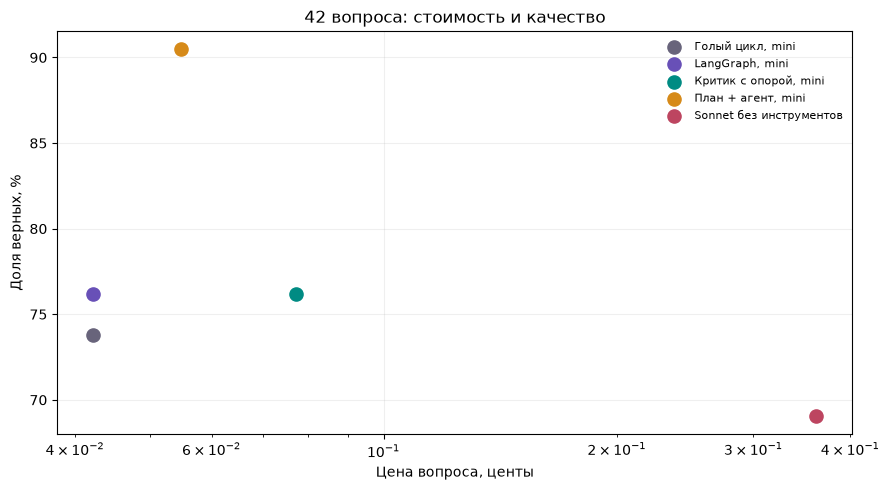

Фактически списано, $: 0.225239


In [29]:
colors = ['#68647B', '#6850B7', '#008B83', '#D68A19', '#BD4560']
fig, ax = plt.subplots(figsize=(9, 5))
for (_, row), color in zip(table.iterrows(), colors):
    ax.scatter(row['центов/вопрос'], row['доля'] * 100, s=90, color=color, label=row['конфигурация'])
ax.set_xscale('log')
ax.set_xlabel('Цена вопроса, центы')
ax.set_ylabel('Доля верных, %')
ax.set_title('42 вопроса: стоимость и качество')
ax.grid(alpha=0.2)
ax.legend(frameon=False, loc='best', fontsize=8)
fig.tight_layout()
if RUN_LIVE:
    table.to_csv(RESULTS_DIR / 'summary.csv', index=False)
    fig.savefig(RESULTS_DIR / 'cost_quality.png', dpi=150)
plt.show()

print('Фактически списано, $:', round(sum(c['cost'] for c in CALLS), 6))

## 9. Потолок на вызовы

Проверка находится в `post`, до `HTTP.post`. Ретраи тоже расходуют лимит.
Вся цепочка критика ограничена 24 чат-вызовами, остальные — 8, обычный агент — шестью шагами.
Демонстрация ниже: лимит в один чат-вызов, попытка второго блокируется кодом.

In [30]:
if RUN_LIVE:
    question = 'Сравни сроки отказа от товара при дистанционной покупке и устранения недостатков. Найди обе нормы через knowledge_base.'
    with run_scope('budget_demo', 'cap-one', 1) as context:
        result = run_agent(question, 'langgraph')
    write_json(RESULTS_DIR / 'budget_demo.json', {'question': question, 'max_calls': 1,
               'calls_made': context.attempts, 'limited': context.limited,
               'answer': result['answer'], 'call_ids': context.call_ids})

demo = json.loads((RESULTS_DIR / 'budget_demo.json').read_text())
print('Вопрос:', demo['question'])
print('Лимит:', demo['max_calls'], '| сделано:', demo['calls_made'], '| сработал:', demo['limited'])
print('Ответ:', demo['answer'])
assert demo['limited'] and demo['calls_made'] == 1
used = [CALLS[i] for i in demo['call_ids']]
assert sum(c['kind'] == 'chat' for c in used) == 1

Вопрос: Сравни сроки отказа от товара при дистанционной покупке и устранения недостатков. Найди обе нормы через knowledge_base.
Лимит: 1 | сделано: 1 | сработал: True
Ответ: NOT_FOUND (достигнут лимит вызовов модели)


## Вывод

- План: 32/42 → 38/42, +14,3 п.п. Цена верного выросла на 9%, но в 8,6 раза ниже Sonnet.
- Критик: 0 исправлений, 0 ухудшений, цена верного в 1,83 раза выше. Дорогое украшение.

У выбранного StateGraph налог на первом запросе — 0 токенов.

In [31]:
HTTP.close()